# Part 1B — Bike Sharing Demand: Time-Series EDA, Cleaning, Clustering & AutoViML

**CMPE 255 | Data Preparation and AutoML**  
**Dataset:** [Kaggle Bike Sharing Demand](https://www.kaggle.com/competitions/bike-sharing-demand/data) (Washington, DC hourly rental demand, 2011–2012).  
**Goal:** understand rental patterns and predict `count` (hourly bicycle rentals) from information available *before* the rental period.

**Run in Google Colab from top to bottom.** The loading cell first tries a public CSV mirror; if unavailable, it prompts for the original Kaggle `train.csv`. The notebook never fabricates data or results. **Save the executed notebook** for GitHub.

**Important:** Kaggle's original labeled `train.csv` contains only selected days of each month; missing hours in the original competition split are **not** ordinary missing values to fill. Consequently, this notebook models observed hourly records and avoids resampling across unobserved competition days. Predictions assume contemporaneous weather features are known or forecast ahead of time.

## 0. Install dependencies (AutoViML is optional until section 8)

In [ ]:
# Base packages are usually preinstalled in Colab.
# AutoViML can have dependency conflicts on newer Python runtimes.
# Run the following cell only when you reach Section 8, using a compatible runtime:
# %pip install autoviml==0.2.2

import sys
print('Python:', sys.version.split()[0])

Python: 3.12.13


## 1. Load the original dataset and inspect its schema

In [ ]:
from pathlib import Path
import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
DATA = Path('/content/bike_train.csv')
MIRROR = 'https://raw.githubusercontent.com/YoungjinBD/data/main/bike_train.csv'

if not DATA.exists():
    try:
        r = requests.get(MIRROR, timeout=30)
        r.raise_for_status()
        candidate = pd.read_csv(io.BytesIO(r.content))
        required = {'datetime', 'season', 'holiday', 'workingday', 'weather',
                    'temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count'}
        if not required.issubset(candidate.columns):
            raise ValueError('Mirror CSV does not match the Kaggle training schema')
        candidate.to_csv(DATA, index=False)
        print('Loaded public mirror:', MIRROR)
    except Exception as e:
        print('Automatic mirror download unavailable:', str(e)[:180])
        print('Download train.csv from https://www.kaggle.com/competitions/bike-sharing-demand/data')
        print('Upload it in the Colab file picker below (no Kaggle API token needed).')
        from google.colab import files
        uploaded = files.upload()
        names = [f for f in uploaded if f.lower().endswith('.csv')]
        if not names:
            raise FileNotFoundError('Please upload Kaggle train.csv and rerun this cell.')
        DATA.write_bytes(uploaded[names[0]])

raw = pd.read_csv(DATA)
required = {'datetime', 'season', 'holiday', 'workingday', 'weather',
            'temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count'}
assert required.issubset(raw.columns), 'Unexpected dataset columns; check that you loaded Kaggle train.csv'
raw['datetime'] = pd.to_datetime(raw['datetime'], errors='coerce')
print('Rows/columns:', raw.shape)
display(raw.head())
raw.info()

Rows/columns: (8708, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-09-03 12:00:00,3,0,0,1,28.70,32.575,61,15.0013,97,160,257
1,2012-08-02 17:00:00,3,0,1,1,33.62,38.635,52,16.9979,90,775,865
2,2012-04-12 06:00:00,2,0,1,1,12.30,14.395,65,16.9979,2,94,96
3,2011-06-19 19:00:00,2,0,0,1,29.52,34.090,62,8.9981,94,217,311
4,2012-02-03 04:00:00,1,0,1,1,10.66,12.880,60,15.0013,0,2,2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8708 entries, 0 to 8707
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    8708 non-null   datetime64[ns]
 1   season      8708 non-null   int64         
 2   holiday     8708 non-null   int64         
 3   workingday  8708 non-null   int64         
 4   weather     8708 non-null   int64         
 5   temp        8708 non-null   float64       
 6   atemp       8708 non-null   float64       
 7   humidity    8708 non-null   int64         
 8   windspeed   8708 non-null   float64       
 9   casual      8708 non-null   int64         
 10  registered  8708 non-null   int64         
 11  count       8708 non-null   int64         
dtypes: datetime64[ns](1), float64(3), int64(8)
memory usage: 816.5 KB


## 2. Exploratory data analysis — before cleaning

Look at dtypes, missing values, duplicates, distributions, seasonality, hourly patterns, and associations. These are descriptive plots, **not proof of causation**.

In [ ]:
print('Missing values by column:')
display(raw.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('Duplicate rows:', raw.duplicated().sum())
print('Duplicate timestamps:', raw['datetime'].duplicated().sum())
print('Dates:', raw['datetime'].min(), 'to', raw['datetime'].max())
display(raw.describe(include='all').T)
print('Count consistency violations:', ((raw['casual'] + raw['registered']) != raw['count']).sum())
print('Rows with invalid time:', raw['datetime'].isna().sum())

Missing values by column:


,missing
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0
casual,0


Duplicate rows: 0
Duplicate timestamps: 0
Dates: 2011-01-01 00:00:00 to 2012-12-19 22:00:00


,count,mean,min,25%,50%,75%,max,std
datetime,8708,2011-12-26 04:34:01.019751936,2011-01-01 00:00:00,2011-07-01 04:45:00,2012-01-01 11:30:00,2012-06-18 22:15:00,2012-12-19 22:00:00,NaN
season,8708.0,2.496899,1.0,1.0,2.0,4.0,4.0,1.118607
holiday,8708.0,0.029513,0.0,0.0,0.0,0.0,1.0,0.169249
workingday,8708.0,0.679835,0.0,0.0,1.0,1.0,1.0,0.466567
weather,8708.0,1.413413,1.0,1.0,1.0,2.0,4.0,0.628714
temp,8708.0,20.151585,0.82,13.94,20.5,26.24,41.0,7.772519
atemp,8708.0,23.566106,2.275,16.665,24.24,31.06,45.455,8.461146
humidity,8708.0,61.778824,0.0,46.75,62.0,77.0,100.0,19.20101
windspeed,8708.0,12.848368,0.0,7.0015,12.998,16.9979,56.9969,8.242156
casual,8708.0,35.888723,0.0,4.0,16.0,48.0,367.0,49.837535


Count consistency violations: 0
Rows with invalid time: 0


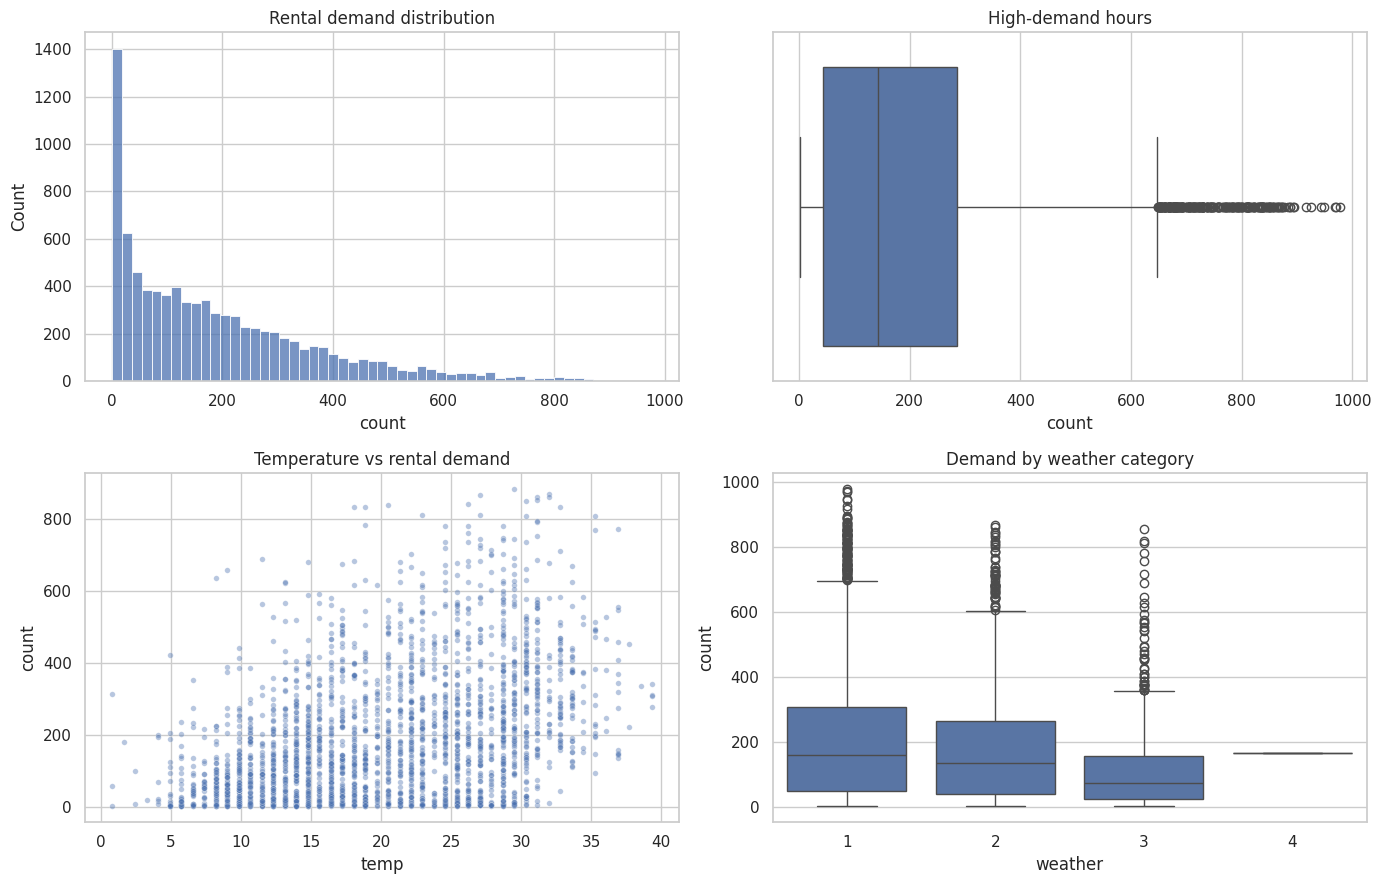

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(raw['count'], bins=55, ax=axes[0, 0]); axes[0, 0].set_title('Rental demand distribution')
sns.boxplot(x=raw['count'], ax=axes[0, 1]); axes[0, 1].set_title('High-demand hours')
sns.scatterplot(data=raw.sample(min(2500, len(raw)), random_state=42), x='temp', y='count',
                alpha=.4, s=16, ax=axes[1, 0]); axes[1, 0].set_title('Temperature vs rental demand')
sns.boxplot(data=raw, x='weather', y='count', ax=axes[1, 1]); axes[1, 1].set_title('Demand by weather category')
plt.tight_layout(); plt.show()

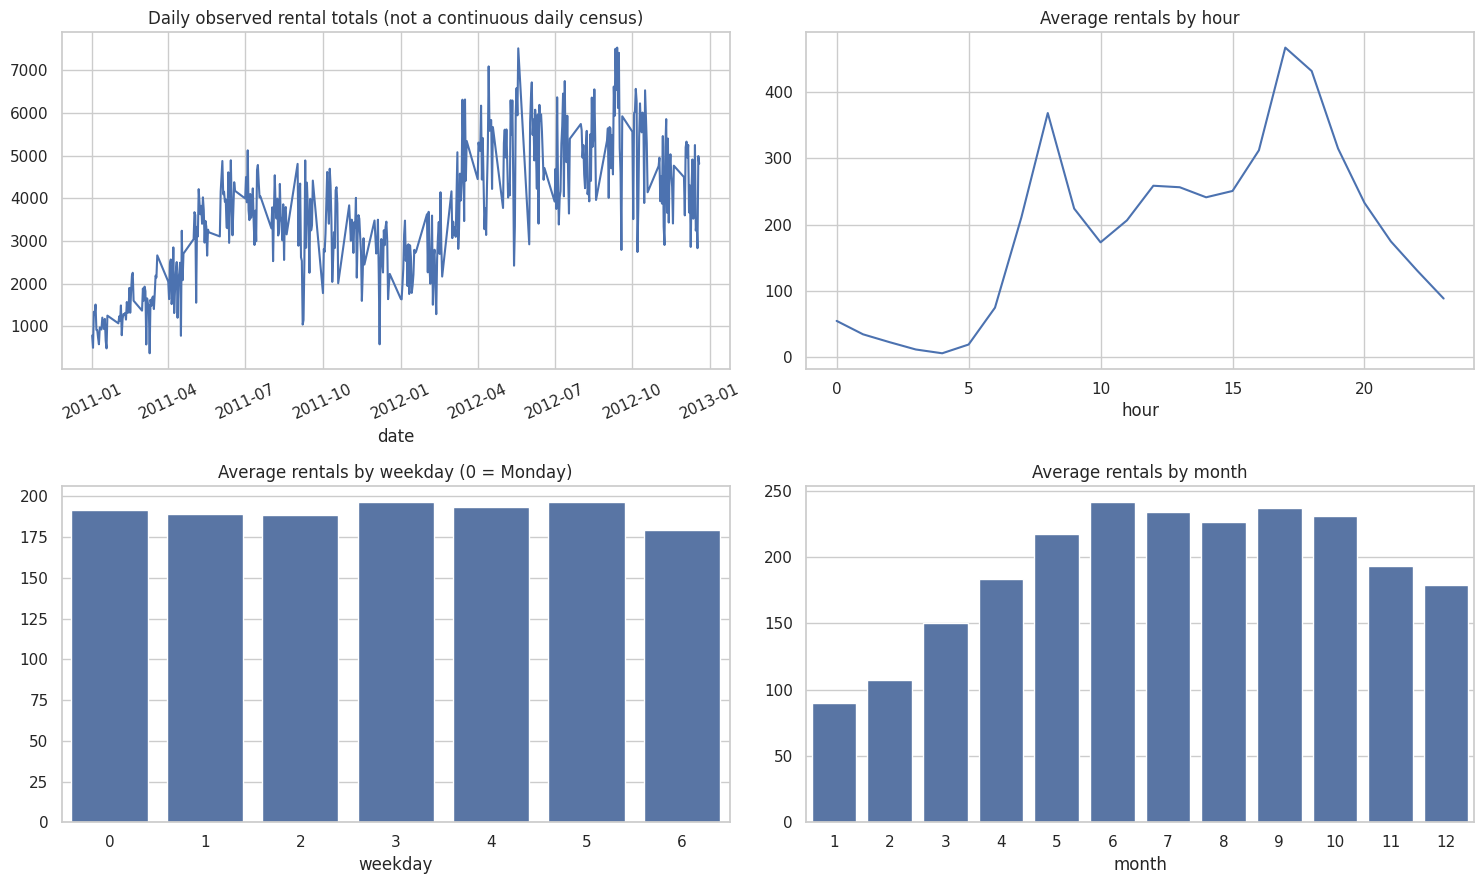

In [ ]:
eda = raw.dropna(subset=['datetime']).copy()
eda['hour'] = eda['datetime'].dt.hour
eda['weekday'] = eda['datetime'].dt.dayofweek
eda['month'] = eda['datetime'].dt.month
eda['date'] = eda['datetime'].dt.date
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
sns.lineplot(x=eda.groupby('date')['count'].sum().index,
             y=eda.groupby('date')['count'].sum().values, ax=axes[0,0])
axes[0,0].set_title('Daily observed rental totals (not a continuous daily census)')
axes[0,0].tick_params(axis='x', rotation=25)
sns.lineplot(x=eda.groupby('hour')['count'].mean().index,
             y=eda.groupby('hour')['count'].mean().values, ax=axes[0,1])
axes[0,1].set_title('Average rentals by hour')
sns.barplot(x=eda.groupby('weekday')['count'].mean().index,
            y=eda.groupby('weekday')['count'].mean().values, ax=axes[1,0])
axes[1,0].set_title('Average rentals by weekday (0 = Monday)')
sns.barplot(x=eda.groupby('month')['count'].mean().index,
            y=eda.groupby('month')['count'].mean().values, ax=axes[1,1])
axes[1,1].set_title('Average rentals by month')
plt.tight_layout(); plt.show()

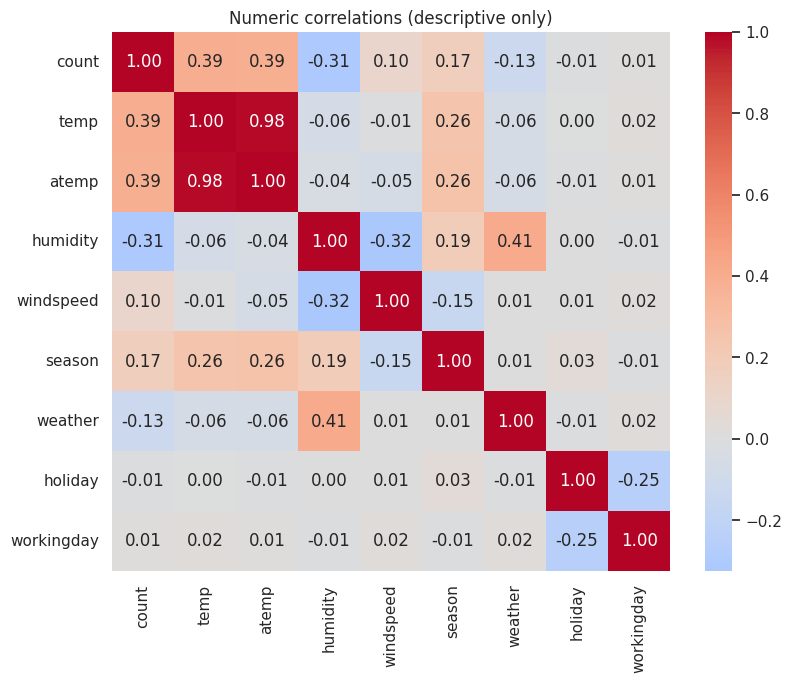

Mean count by season:


,mean,median,count
season,,,
1,116.077487,78.0,2181
2,214.119709,169.0,2197
3,232.601301,190.5,2152
4,201.022039,163.5,2178


In [ ]:
corr_columns = ['count','temp','atemp','humidity','windspeed','season','weather','holiday','workingday']
plt.figure(figsize=(9,7))
sns.heatmap(raw[corr_columns].corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Numeric correlations (descriptive only)'); plt.show()
print('Mean count by season:')
display(raw.groupby('season')['count'].agg(['mean','median','count']))

## 3. Data quality checks and chronological train/test split

Drop invalid dates, duplicate timestamps and impossible targets. **Never use `casual` or `registered` as predictors:** their sum equals `count`, which would leak the target. We deliberately split by timestamp **before fitting imputers, scalers, clusters or anomaly detectors**.

In [ ]:
df = raw.copy()
original_n = len(df)
df = df.dropna(subset=['datetime','count'])
df = df.loc[df['count'].ge(0)].copy()
df = df.sort_values('datetime').drop_duplicates(subset='datetime', keep='first').reset_index(drop=True)
print('Rows removed for invalid timestamp/target/duplicate timestamps:', original_n - len(df))
# Chronological split on Kaggle's labeled rows (not Kaggle's public unlabeled competition test file).
split_at = int(len(df) * 0.8)
train_raw = df.iloc[:split_at].copy()
valid_raw = df.iloc[split_at:].copy()
assert train_raw['datetime'].max() < valid_raw['datetime'].min()
print('Train:', train_raw.shape, train_raw.datetime.min(), 'through', train_raw.datetime.max())
print('Validation:', valid_raw.shape, valid_raw.datetime.min(), 'through', valid_raw.datetime.max())

Rows removed for invalid timestamp/target/duplicate timestamps: 0
Train: (6966, 12) 2011-01-01 00:00:00 through 2012-08-04 20:00:00
Validation: (1742, 12) 2012-08-04 21:00:00 through 2012-12-19 22:00:00


## 4. Clean, impute, and engineer time-series features

Impute *input* columns using training-set statistics; retain a missingness indicator. For data validity, humidity must be in [0, 100] and numerical weather measurements cannot be negative. We treat zero wind speed as a recorded value rather than automatically labeling it missing. Calendar features are deterministic and available at prediction time.

In [ ]:
from sklearn.impute import SimpleImputer

numeric_weather = ['temp','atemp','humidity','windspeed']
category_flags = ['season','holiday','workingday','weather']

def clean_inputs(frame):
    d = frame.copy()
    d.loc[~d['humidity'].between(0, 100), 'humidity'] = np.nan
    for c in ['temp','atemp','windspeed']:
        d.loc[~np.isfinite(pd.to_numeric(d[c], errors='coerce')), c] = np.nan
    d.loc[d['windspeed'] < 0, 'windspeed'] = np.nan
    for c in category_flags:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    for c in numeric_weather + category_flags:
        d[c + '_missing'] = d[c].isna().astype(int)
    return d

train_clean, valid_clean = clean_inputs(train_raw), clean_inputs(valid_raw)
imp_num = SimpleImputer(strategy='median')
imp_cat = SimpleImputer(strategy='most_frequent')
train_clean[numeric_weather] = imp_num.fit_transform(train_clean[numeric_weather])
valid_clean[numeric_weather] = imp_num.transform(valid_clean[numeric_weather])
train_clean[category_flags] = imp_cat.fit_transform(train_clean[category_flags])
valid_clean[category_flags] = imp_cat.transform(valid_clean[category_flags])

def add_calendar_features(d):
    d = d.copy()
    t = d['datetime']
    d['hour'] = t.dt.hour
    d['weekday'] = t.dt.dayofweek
    d['month'] = t.dt.month
    d['year'] = t.dt.year
    d['day_of_month'] = t.dt.day
    d['hour_sin'] = np.sin(2*np.pi*d['hour']/24)
    d['hour_cos'] = np.cos(2*np.pi*d['hour']/24)
    d['month_sin'] = np.sin(2*np.pi*d['month']/12)
    d['month_cos'] = np.cos(2*np.pi*d['month']/12)
    return d

train_clean = add_calendar_features(train_clean)
valid_clean = add_calendar_features(valid_clean)
print('Missing inputs after imputation — train:', train_clean[numeric_weather+category_flags].isna().sum().sum())
print('Missing inputs after imputation — validation:', valid_clean[numeric_weather+category_flags].isna().sum().sum())

Missing inputs after imputation — train: 0
Missing inputs after imputation — validation: 0


## 5. Detect unusual conditions and cluster weather/time patterns

Fit on train only. **Anomaly detection uses input features, not rental count**, and flags should be reviewed before removal: a genuine holiday demand spike is not necessarily bad data. This notebook removes only a small percentage of training input outliers for the cleaned modeling experiment and leaves validation untouched.

Silhouette scores: {2: 0.2512937986718359, 3: 0.2048591539330889, 4: 0.17992888335907906, 5: 0.18281247874666845}
Selected k: 2


,temp,humidity,windspeed,hour,count
cluster,,,,,
0,13.32,59.57,13.92,11.18,119.64
1,26.63,62.21,12.29,11.94,228.06


Flagged anomalies in training: 140
Flagged anomalies in validation (NOT removed): 35


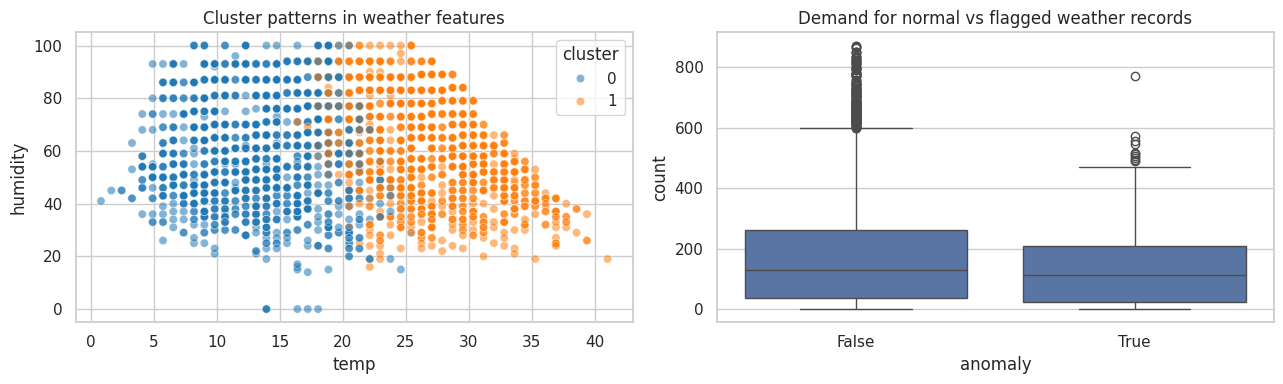

Training after anomaly exclusion: 6826 / original: 6966


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pattern_features = ['temp','atemp','humidity','windspeed','hour_sin','hour_cos','month_sin','month_cos']
pattern_scaler = StandardScaler()
train_pattern = pattern_scaler.fit_transform(train_clean[pattern_features])
valid_pattern = pattern_scaler.transform(valid_clean[pattern_features])

# Compare a few cluster sizes using only training inputs.
cluster_trials = {}
for k in [2,3,4,5]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(train_pattern)
    idx = np.random.default_rng(42).choice(len(train_pattern), size=min(2000,len(train_pattern)), replace=False)
    cluster_trials[k] = silhouette_score(train_pattern[idx], km.labels_[idx])
print('Silhouette scores:', cluster_trials)
best_k = max(cluster_trials, key=cluster_trials.get)
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
train_clean['cluster'] = kmeans.fit_predict(train_pattern)
valid_clean['cluster'] = kmeans.predict(valid_pattern)
print('Selected k:', best_k)
display(train_clean.groupby('cluster')[['temp','humidity','windspeed','hour','count']].mean().round(2))

isoforest = IsolationForest(n_estimators=150, contamination=0.02, random_state=42)
train_clean['anomaly'] = (isoforest.fit_predict(train_pattern) == -1)
valid_clean['anomaly'] = (isoforest.predict(valid_pattern) == -1)
print('Flagged anomalies in training:', int(train_clean['anomaly'].sum()))
print('Flagged anomalies in validation (NOT removed):', int(valid_clean['anomaly'].sum()))

fig, axes = plt.subplots(1,2,figsize=(13,4))
sns.scatterplot(data=train_clean.sample(min(3000,len(train_clean)),random_state=42),
                x='temp',y='humidity',hue='cluster',palette='tab10',alpha=.55,ax=axes[0])
axes[0].set_title('Cluster patterns in weather features')
sns.boxplot(data=train_clean,x='anomaly',y='count',ax=axes[1])
axes[1].set_title('Demand for normal vs flagged weather records')
plt.tight_layout();plt.show()

train_model = train_clean.loc[~train_clean['anomaly']].copy()
valid_model = valid_clean.copy()
print('Training after anomaly exclusion:', len(train_model), '/ original:', len(train_clean))

## 6. Feature processing, selection and leakage prevention

No `casual`, `registered`, raw `datetime`, or `anomaly` flag is included as a predictor. A simple univariate selection step (fit on training only) documents candidate features; the final models use the full approved feature set to retain interpretable calendar signals.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression

exclude = {'count','casual','registered','datetime','anomaly'}
features = [c for c in train_model.columns if c not in exclude and pd.api.types.is_numeric_dtype(train_model[c])]
print('Candidate features:', features)
assert not {'casual','registered','count'}.intersection(features)
select = SelectKBest(score_func=f_regression, k=min(12, len(features)))
select.fit(train_model[features], train_model['count'])
selection = pd.DataFrame({'feature': features,'score':np.nan_to_num(select.scores_, nan=0)})
display(selection.sort_values('score',ascending=False).head(15))
selected = list(selection.sort_values('score',ascending=False).head(min(12,len(features)))['feature'])
print('Selected top features for report:',selected)

Candidate features: ['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'temp_missing', 'atemp_missing', 'humidity_missing', 'windspeed_missing', 'season_missing', 'holiday_missing', 'workingday_missing', 'weather_missing', 'hour', 'weekday', 'month', 'year', 'day_of_month', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'cluster']


,feature,score
4,temp,1508.267775
5,atemp,1482.663647
21,hour_sin,1468.978039
16,hour,1341.704330
22,hour_cos,1287.022921
6,humidity,834.885899
25,cluster,769.177520
24,month_cos,483.583273
19,year,350.401997
3,weather,134.244227


Selected top features for report: ['temp', 'atemp', 'hour_sin', 'hour', 'hour_cos', 'humidity', 'cluster', 'month_cos', 'year', 'weather', 'windspeed', 'month']


## 7. Reproducible forecasting baseline and evaluation

A **chronological validation set** estimates performance on later observations. The baseline uses a median imputer and HistGradientBoosting. Scores are measured against actual future-hour demand. Kaggle competition uses RMSLE; we also report MAE and RMSE.

,model,MAE,RMSE,RMSLE,R2
0,Histogram Gradient Boosting,42.196052,63.374490,0.417519,0.915143
1,Random Forest,53.822349,81.755775,0.359767,0.858780


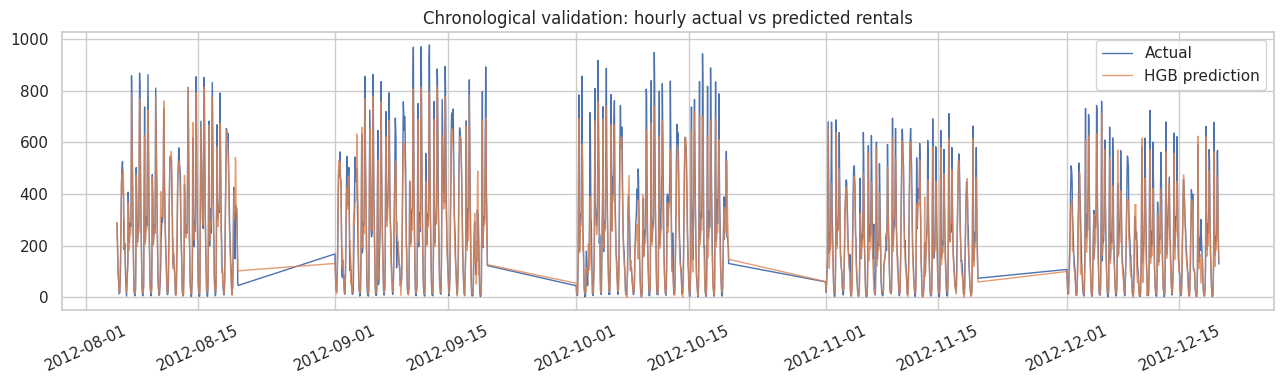

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_squared_log_error

X_train, y_train = train_model[features], train_model['count']
X_valid, y_valid = valid_model[features], valid_model['count']

models = {
    'Histogram Gradient Boosting': HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=25,random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=120,max_depth=18,min_samples_leaf=2,n_jobs=-1,random_state=42),
}
results = []
for name, mdl in models.items():
    mdl.fit(X_train, y_train)
    pred = np.clip(mdl.predict(X_valid),0,None)
    results.append({'model':name, 'MAE':mean_absolute_error(y_valid,pred),
                    'RMSE':np.sqrt(mean_squared_error(y_valid,pred)),
                    'RMSLE':np.sqrt(mean_squared_log_error(y_valid,pred)),
                    'R2':r2_score(y_valid,pred)})
    if name == 'Histogram Gradient Boosting':
        baseline_predictions = pred
scores = pd.DataFrame(results).sort_values('RMSE')
display(scores)
plt.figure(figsize=(13,4))
plt.plot(valid_model['datetime'],y_valid.values,label='Actual',linewidth=1)
plt.plot(valid_model['datetime'],baseline_predictions,label='HGB prediction',linewidth=1,alpha=.8)
plt.title('Chronological validation: hourly actual vs predicted rentals')
plt.legend();plt.xticks(rotation=25);plt.tight_layout();plt.show()

## 8. AutoViML: two model families (required for Part 1)

**First install** `autoviml==0.2.2` in a compatible Colab Python 3.12 environment, as done for Part 1A. Start with the linear model; run the forest version afterwards. To keep runtime manageable, use up to 4,000 of the *latest* clean training records. AutoViML performs its own internal validation, which **is not a chronological evaluation**; report those scores separately from Section 7. The external validation set is passed for predictions, but AutoViML's printed internal CV metrics should not be claimed as chronological test metrics. The code saves family-specific output files before the next run overwrites AutoViML's default `count` output directory.

In [ ]:
# Run once if AutoViML is not already installed. Uncomment and execute:
%pip install autoviml==0.2.2

from autoviml.Auto_ViML import Auto_ViML
print('AutoViML imported!')

Imported Auto_ViML version: 0.2.02. Call using:
             m, feats, trainm, testm = Auto_ViML(train, target, test,
                            sample_submission='',
                            scoring_parameter='', KMeans_Featurizer=False,
                            hyper_param='RS',feature_reduction=True,
                             Boosting_Flag='CatBoost', Binning_Flag=False,
                            Add_Poly=0, Stacking_Flag=False,Imbalanced_Flag=False,
                            GPU_flag=False, verbose=1)
            

Imported Auto_NLP version: 0.1.01.. Call using:
     train_nlp, test_nlp, nlp_pipeline, predictions = Auto_NLP(
                nlp_column, train, test, target, score_type='balanced_accuracy',
                modeltype='Classification',top_num_features=200, verbose=0,
                build_model=True)
AutoViML imported!


AutoViML training: (4000, 27) external validation inputs: (1742, 26)
Starting Linear
##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (4000, 27)
    Training Set Memory Usage = 0.76 MB
Test Set Shape = (1742, 26)
    Test Set Memory Usage = 0.31 MB
Single_Label Target: ['count']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    26 Predictors classified...
    8 variables removed since they were ID or low-information variables
########################################################

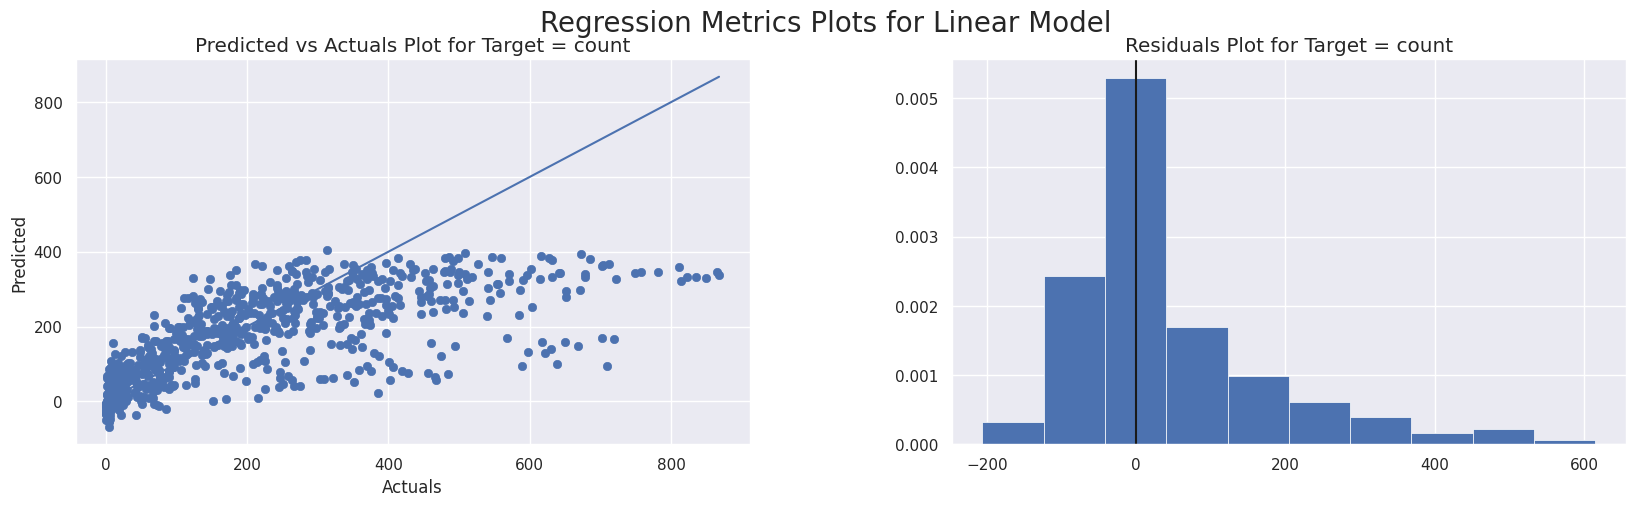

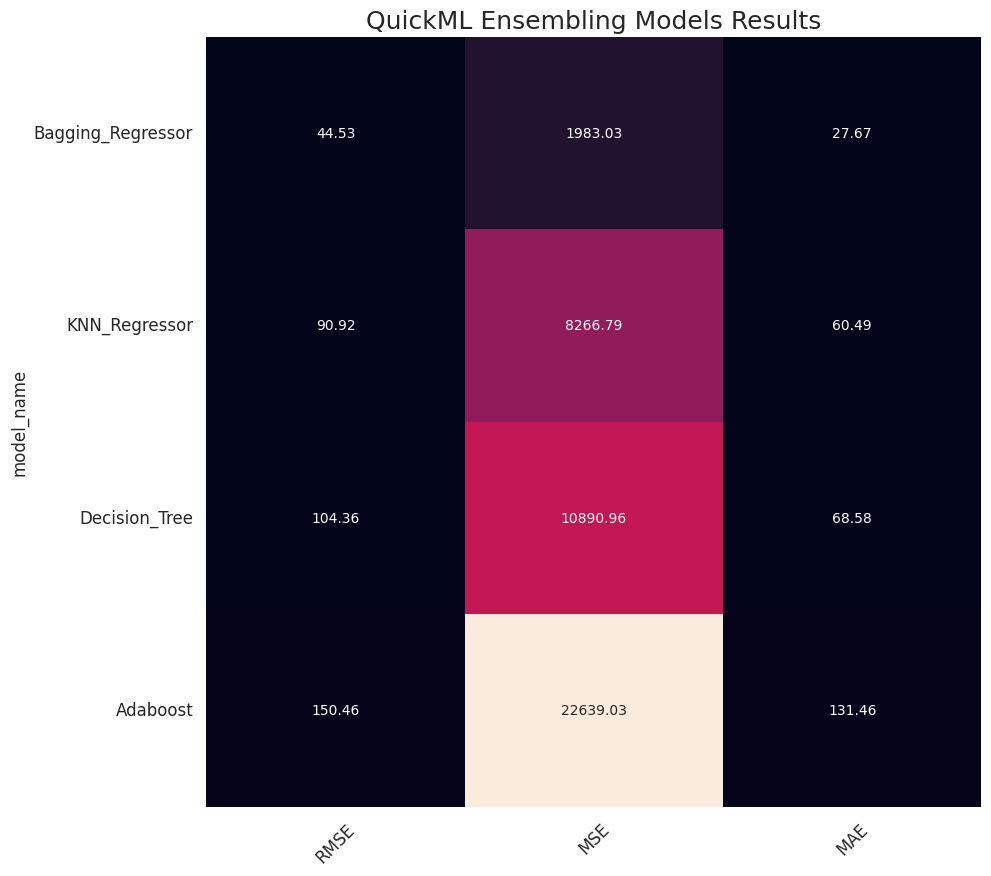

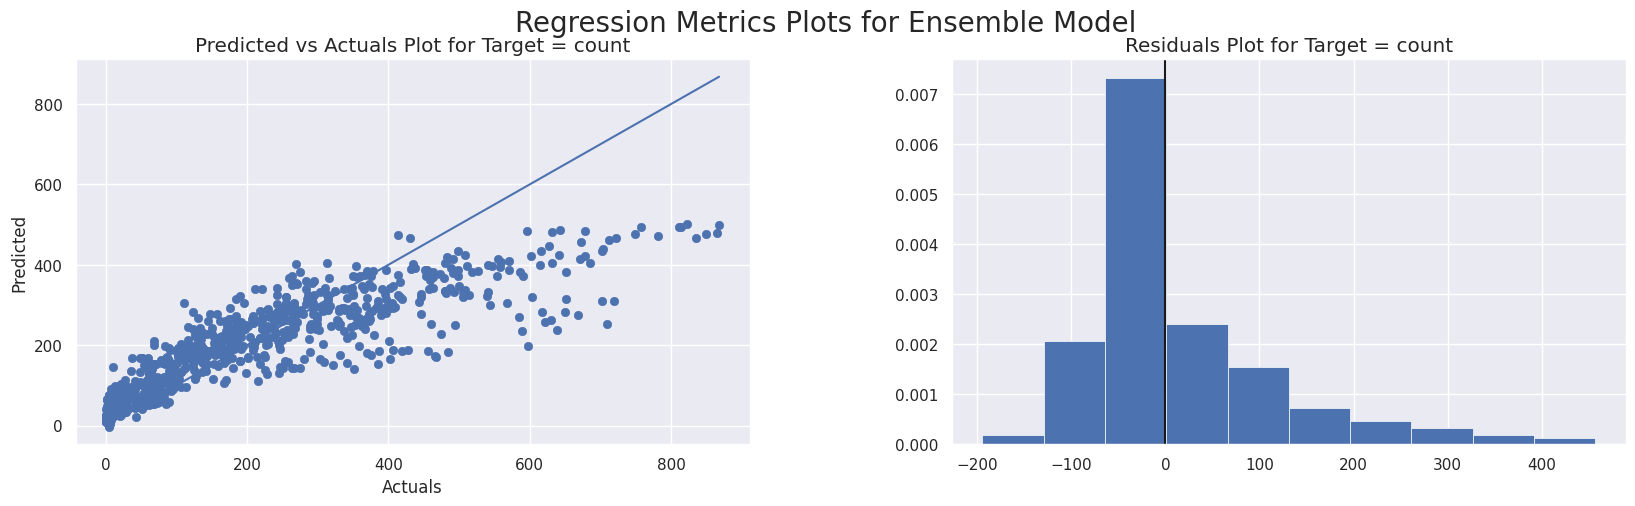

In [ ]:
import time
import shutil

# Sample latest training data only; keep entire later validation set separate.
auto_train = train_model.sort_values('datetime').tail(min(4000,len(train_model)))[features+['count']].copy()
auto_valid = valid_model[features].copy()
print('AutoViML training:',auto_train.shape,'external validation inputs:',auto_valid.shape)

def run_autoviml(label, boosting_flag):
    start = time.time()
    print('Starting',label)
    model, selected_features, modified_train, modified_test = Auto_ViML(
        auto_train.copy(), 'count', auto_valid.copy(), '',
        hyper_param='RS', feature_reduction=False,
        Boosting_Flag=boosting_flag, scoring_parameter='rmse', verbose=0
    )
    print(label,'completed in',round(time.time()-start,1),'seconds')
    print('AutoViML selected features:',selected_features)
    src = Path('count')
    dest = Path('autoviml_outputs') / label.replace(' ','_')
    if src.exists():
        dest.mkdir(parents=True,exist_ok=True)
        for p in src.glob('*.csv'):
            shutil.copy2(p, dest/p.name)
        print('Saved AutoViML output CSVs to',dest)
    return model, selected_features, modified_train, modified_test

linear_model,linear_features,linear_train,linear_valid = run_autoviml('Linear',None)

Starting Forests
##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (4000, 27)
    Training Set Memory Usage = 0.76 MB
Test Set Shape = (1742, 26)
    Test Set Memory Usage = 0.31 MB
Single_Label Target: ['count']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    26 Predictors classified...
    8 variables removed since they were ID or low-information variables
##############################################################################
######     D A T A    P R E P A R A T I O N  

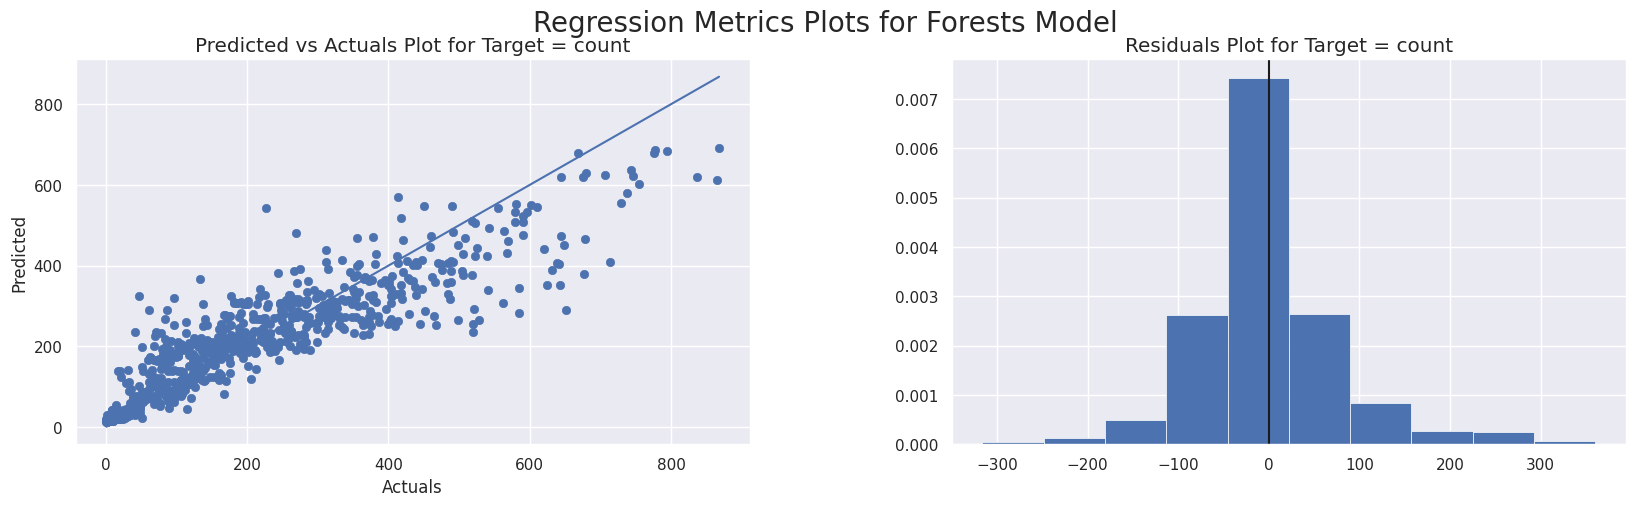

In [ ]:
# Run separately after inspecting the linear model result. Forest search may take minutes.
forest_model,forest_features,forest_train,forest_valid = run_autoviml('Forests',False)

## Part 1B — AutoViML Model Comparison and Conclusion

AutoViML was used to develop regression models predicting hourly bicycle rental demand. Each configuration used 4,000 training samples, and 18 features were retained after automated variable processing.

Three model configurations were evaluated:

| Model | MAE | RMSE |
|---|---:|---:|
| Linear | 90.49 | 139.41 |
| Linear-run Ensemble | 70.35 | 102.81 |
| Forests | 53.26 | 77.57 |

The Forests model achieved the lowest validation errors, reducing RMSE by approximately 44.4% compared with the Linear model. The best Forests hyperparameters included 251 estimators, a maximum depth of 7, and a minimum of 3 samples per leaf.

The modeling features included weather information, temperature, humidity, holiday indicators, and engineered time features such as hour, weekday, month, and cyclical sine/cosine transformations.

These findings demonstrate the importance of nonlinear modeling for predicting bicycle rental demand. AutoViML automated feature processing, hyperparameter optimization, and model evaluation.

**Limitations:** The reported scores came from AutoViML's internal validation sets. A separate chronological holdout evaluation is necessary to assess future forecasting performance. The Forests ensemble stage also encountered an error, although the standalone model trained successfully.

Overall, the Forests model was the strongest configuration in this experiment, based on the available validation results.